# 08 Evaluation
Reconstruction metrics (vertex, point-set, surface), CRPS, coverage, sparsification, risk-coverage, stress tests, ablations, the ensemble, and
bootstrap intervals over test skulls. The test split is for final reporting only. All numbers are read from saved results and are errors against a
**synthetic** face.

In [1]:
import sys, pathlib, os, json
ROOT = pathlib.Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import numpy as np, matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
REAL, RUN, RES = 'UNCERTAFACE_DATA_REAL', 'experiments/runs/face_v3_pn', 'reports/results/face_v3_pn'
if not pathlib.Path(REAL).exists():
    raise SystemExit('Build the real-skull dataset first (README: fetch_mug500, prepare_mug500, build_dataset).')

In [2]:
r = json.load(open(RES + '/results.json')); b = json.load(open('reports/baselines.json')); o = json.load(open('reports/oracle_floor.json'))
print('test views:', r['n_test'])
for k, v in r['reconstruction'].items(): print(f"  {k:18s} {v['mean']:.2f} +- {v['std']:.2f} mm")
print('mean-face baseline vertex RMSE: %.2f mm | oracle floor: %.2f mm' % (b['mean_template']['test']['vertex_rmse']['mean'], o['floor_rmse_mm']))
sev = r['reconstruction_by_severity']
print('by severity:', {k: round(v['vertex_rmse']['mean'], 2) for k, v in sev.items()})

test views: 48
  vertex_mae         2.34 +- 0.52 mm
  vertex_rmse        5.86 +- 1.28 mm
  chamfer            3.26 +- 0.73 mm
  hausdorff          16.86 +- 4.68 mm
  point_to_surface   2.62 +- 0.85 mm
  surface_error      2.61 +- 0.83 mm
mean-face baseline vertex RMSE: 8.11 mm | oracle floor: 1.34 mm
by severity: {'mild': 5.21, 'moderate': 5.53, 'severe': 6.02, 'extreme': 6.7}


In [3]:
ci = json.load(open(RES + '/bootstrap_ci.json'))
print(f"{ci['n_test_skulls']} test skulls, bootstrap over skulls ({ci['n_boot']} draws), 95% intervals:")
for k in ['model_rmse_mm', 'baseline_rmse_mm', 'coverage90_calibrated']:
    print(f"  {k:24s} {ci[k]['estimate']:.3f}  [{ci[k]['ci95'][0]:.3f}, {ci[k]['ci95'][1]:.3f}]")
g = ci['relative_gain_over_baseline']
print(f"  gain over mean-face baseline {g['estimate']*100:.1f}%  [{g['ci95'][0]*100:.1f}%, {g['ci95'][1]*100:.1f}%]; model better in {g['share_of_draws_model_better']*100:.2f}% of draws")
print(ci['note'])

6 test skulls, bootstrap over skulls (10000 draws), 95% intervals:
  model_rmse_mm            5.864  [5.378, 6.351]
  baseline_rmse_mm         8.105  [7.213, 9.078]
  coverage90_calibrated    0.910  [0.889, 0.936]
  gain over mean-face baseline 27.7%  [13.8%, 37.2%]; model better in 99.98% of draws
skulls are resampled, not views; with this few skulls the intervals are wide and should be read as a range, not a precise error bar


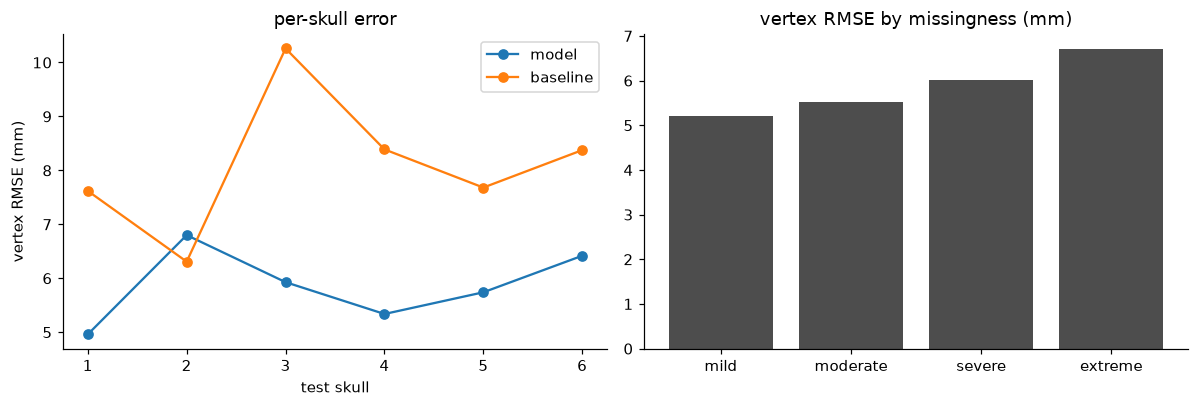

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name in ['model_rmse_mm', 'baseline_rmse_mm']: ax[0].plot(range(1, 7), ci[name]['per_skull'], 'o-', label=name.replace('_rmse_mm', ''))
ax[0].set_xlabel('test skull'); ax[0].set_ylabel('vertex RMSE (mm)'); ax[0].legend(); ax[0].set_title('per-skull error')
ax[1].bar(list(sev), [v['vertex_rmse']['mean'] for v in sev.values()], color='0.3'); ax[1].set_title('vertex RMSE by missingness (mm)')
plt.tight_layout(); plt.show()

{'sparsification_error_mm': 0.86, 'normalised_se': 0.374, 'aurc_mm': 3.515, 'aurc_oracle_mm': 2.655, 'aurc_random_mm': 4.953}
risk (mean error mm) at retained coverage: {'1': 4.95, '0.9': 4.53, '0.75': 4.07, '0.5': 3.49, '0.25': 2.82, '0.1': 2.61}
best-of-N (oracle-selected, NOT a single prediction): {'n_samples': 10, 'single_prediction_rmse_mm': 6.0, 'best_of_n_rmse_mm': 9.09, 'mean_sampled_rmse_mm': 9.27}


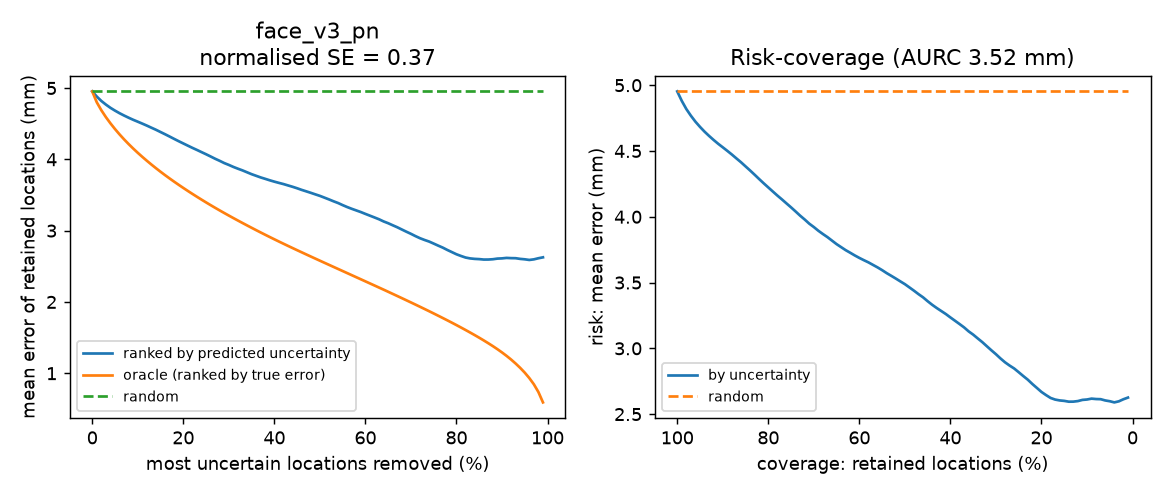

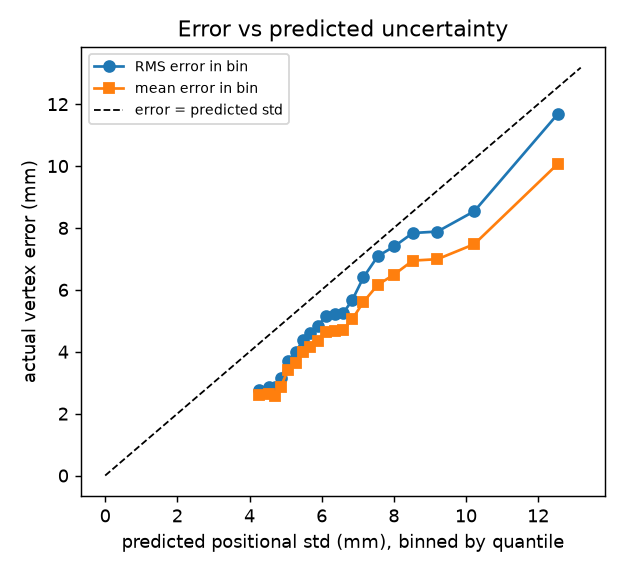

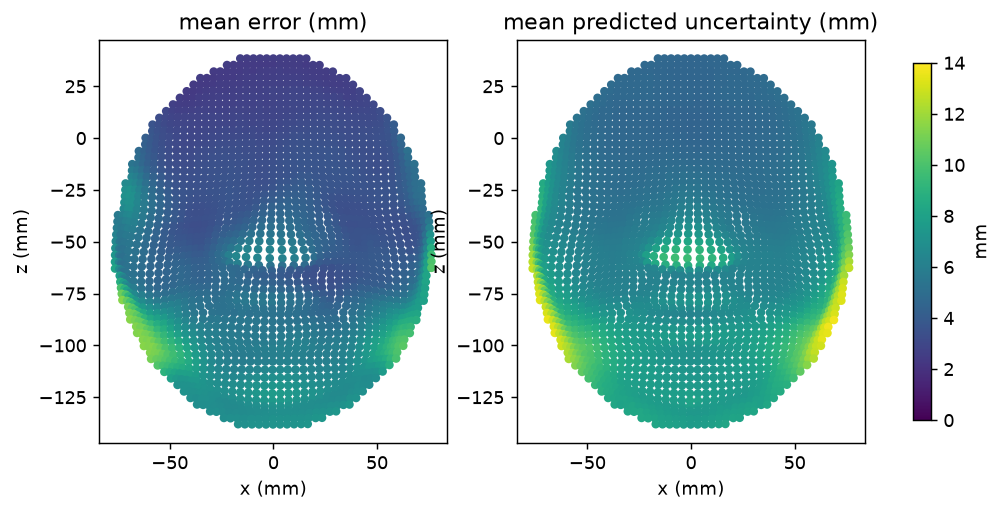

In [5]:
sp = r['sparsification']; print({k: round(v, 3) for k, v in sp.items()})
print('risk (mean error mm) at retained coverage:', {k: round(v, 2) for k, v in r['risk_coverage'].items()})
print('best-of-N (oracle-selected, NOT a single prediction):', {k: (round(v, 2) if isinstance(v, float) else v) for k, v in r['best_of_n'].items() if k != 'note'})
from IPython.display import Image, display
for f in ['sparsification.png', 'error_vs_uncertainty.png', 'spatial_maps.png']: display(Image(RES + '/' + f))

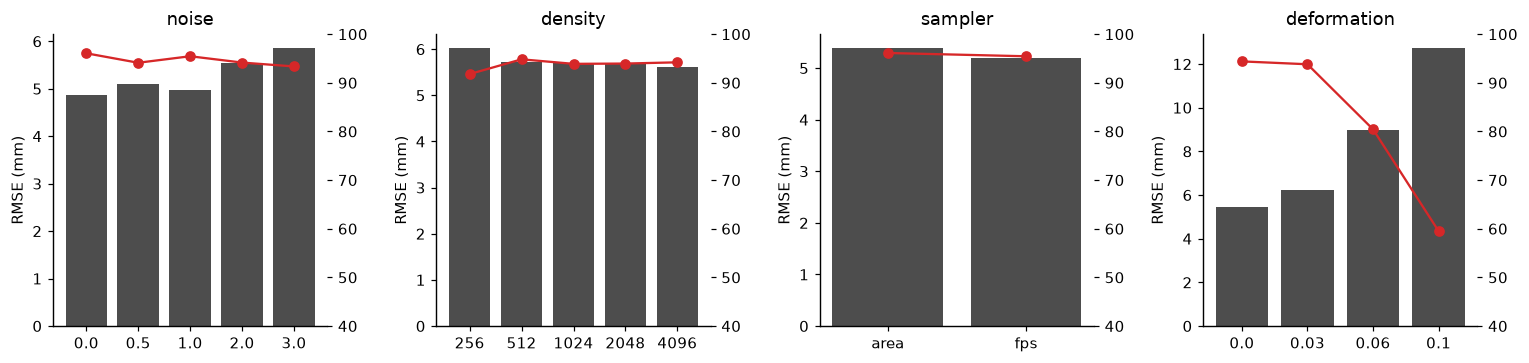

deformation sweep: error rises but predicted std barely moves -> [('0.0', 5.4, 6.4), ('0.03', 6.2, 6.5), ('0.06', 9.0, 6.6), ('0.1', 12.7, 6.8)]


In [6]:
sw = r['stress_controlled']
fig, ax = plt.subplots(1, 4, figsize=(14, 3.4))
for a, f in zip(ax, ['noise', 'density', 'sampler', 'deformation']):
    rows = sw[f]; a.bar([str(x['group']) for x in rows], [x['rmse_mm'] for x in rows], color='0.3')
    a2 = a.twinx(); a2.plot([str(x['group']) for x in rows], [100 * x['cov90_raw'] for x in rows], 'o-', c='tab:red'); a2.set_ylim(40, 100)
    a.set_title(f); a.set_ylabel('RMSE (mm)')
plt.tight_layout(); plt.show()
print('deformation sweep: error rises but predicted std barely moves ->', [(x['group'], round(x['rmse_mm'], 1), round(x['mean_pos_std_mm'], 1)) for x in sw['deformation']])

In [7]:
import csv
rows = list(csv.DictReader(open('reports/ablation_table.csv')))
print(f"{'variant':18s} {'test RMSE':>10} {'cov90 raw':>10} {'cov90 cal':>10}")
f3 = lambda v: f"{float(v):.3f}" if v not in ('', None) else 'n/a'
for x in rows: print(f"{x['variant']:18s} {float(x['test_vertex_rmse_mm']):10.2f} {f3(x['cov90_raw']):>10} {f3(x['cov90_global']):>10}")
full = [float(x['test_vertex_rmse_mm']) for x in rows if x['variant'].startswith('full')]
print('seed-to-seed spread of the identical model: %.2f - %.2f mm; differences smaller than this are noise' % (min(full), max(full)))

variant             test RMSE  cov90 raw  cov90 cal
full                     6.79      0.964      0.895
full_seed1               7.93      0.975      0.904
full_seed2               6.53      0.970      0.899
deterministic            6.98        n/a        n/a
no_surface               6.85      0.963      0.895
no_missing_info          7.07      0.966      0.900
encoder_pointnet         5.91      0.972      0.919
points_2048              6.96      0.974      0.897
points_4096              6.75      0.976      0.891
seed-to-seed spread of the identical model: 6.53 - 7.93 mm; differences smaller than this are noise


In [8]:
e = json.load(open('reports/results/ensemble3/results.json'))
print('single members (mm):', {k: round(v, 2) for k, v in e['single_member_rmse_mm'].items()}, '| ensemble:', round(e['ensemble_reconstruction']['vertex_rmse']['mean'], 2))
print('epistemic share of total variance: %.3f' % e['epistemic_share_of_total_variance'])
for k, v in e['uncertainty'].items(): print(f"  {k:10s} mean std {v['mean_std_mm']:.2f} mm | raw cov90 {v['cov90_raw']:.3f} | err-vs-std Spearman {v['pooled_spearman_err_vs_std']:.3f}")

single members (mm): {'abl_full': 6.96, 'abl_full_seed1': 8.06, 'abl_full_seed2': 6.67} | ensemble: 6.8
epistemic share of total variance: 0.048
  aleatoric  mean std 4.99 mm | raw cov90 0.977 | err-vs-std Spearman 0.480
  epistemic  mean std 0.77 mm | raw cov90 0.229 | err-vs-std Spearman 0.266
  combined   mean std 5.09 mm | raw cov90 0.980 | err-vs-std Spearman 0.477
